## Import Libraries

In [28]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## Configuration
Change only this cell when reusing the notebook for another pose.

In [29]:
POSE_NAME = "Bhujangasana"
MODEL_FILENAME = "bhujangasana_rf.pkl"

FEATURES = [
    "left_knee",
    "right_knee",
    "left_hip",
    "right_hip",
    "left_shoulder",
    "right_shoulder"
]

TARGET_COL = "target"
RANDOM_STATE = 42

## Load and Merge Datasets (Train / Val / Test)
Loads the pre-split correct/incorrect CSVs, merges them, and shuffles rows.

In [30]:
def load_and_merge(split_name):
    correct_path = f"{split_name}/correct_{split_name}.csv"
    incorrect_path = f"{split_name}/incorrect_{split_name}.csv"

    if not os.path.exists(correct_path) or not os.path.exists(incorrect_path):
        raise FileNotFoundError(
            f"Missing files for split '{split_name}'. "
            f"Expected: {correct_path} and {incorrect_path}"
        )

    correct_df = pd.read_csv(correct_path)
    incorrect_df = pd.read_csv(incorrect_path)

    df = pd.concat([correct_df, incorrect_df], ignore_index=True)
    df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    return df

train_df = load_and_merge("train")
val_df   = load_and_merge("val")
test_df  = load_and_merge("test")

print("Train Shape :", train_df.shape)
print("Val Shape   :", val_df.shape)
print("Test Shape  :", test_df.shape)

Train Shape : (2142, 11)
Val Shape   : (459, 11)
Test Shape  : (460, 11)


## Sanity Checks

In [31]:
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    missing = df[FEATURES + [TARGET_COL]].isnull().sum().sum()
    print(f"{name} missing values: {missing}")
    assert missing == 0, f"{name} split has missing values in required columns"

print("\nClass Distribution")
print("Train:\n", train_df[TARGET_COL].value_counts())
print("\nVal:\n", val_df[TARGET_COL].value_counts())
print("\nTest:\n", test_df[TARGET_COL].value_counts())

Train missing values: 0
Val missing values: 0
Test missing values: 0

Class Distribution
Train:
 target
1    1333
0     809
Name: count, dtype: int64

Val:
 target
1    286
0    173
Name: count, dtype: int64

Test:
 target
1    286
0    174
Name: count, dtype: int64


## Feature / Target Split

In [32]:
X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURES],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]

## Train Random Forest

In [33]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

rf.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


## Train vs Validation Accuracy (Overfitting Check)

In [34]:
train_pred = rf.predict(X_train)
val_pred   = rf.predict(X_val)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy   = accuracy_score(y_val, val_pred)

print(f"Train Accuracy      : {train_accuracy*100:.2f}%")
print(f"Validation Accuracy : {val_accuracy*100:.2f}%")
print(f"Gap (Train - Val)   : {(train_accuracy - val_accuracy)*100:.2f}%")

if (train_accuracy - val_accuracy) > 0.10:
    print("Warning: large train-val gap, model may be overfitting")

print("\nValidation Classification Report")
print(classification_report(y_val, val_pred, target_names=["Incorrect", "Correct"]))

Train Accuracy      : 100.00%
Validation Accuracy : 100.00%
Gap (Train - Val)   : 0.00%

Validation Classification Report
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       173
     Correct       1.00      1.00      1.00       286

    accuracy                           1.00       459
   macro avg       1.00      1.00      1.00       459
weighted avg       1.00      1.00      1.00       459



## Test Set Evaluation

In [35]:
test_pred = rf.predict(X_test)

test_accuracy  = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred)
test_recall    = recall_score(y_test, test_pred)
test_f1        = f1_score(y_test, test_pred)

print(f"Test Accuracy  : {test_accuracy*100:.2f}%")
print(f"Test Precision : {test_precision*100:.2f}%")
print(f"Test Recall    : {test_recall*100:.2f}%")
print(f"Test F1 Score  : {test_f1*100:.2f}%")

print("\nFull Classification Report (Test)")
print(classification_report(y_test, test_pred, target_names=["Incorrect", "Correct"]))

Test Accuracy  : 100.00%
Test Precision : 100.00%
Test Recall    : 100.00%
Test F1 Score  : 100.00%

Full Classification Report (Test)
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00       174
     Correct       1.00      1.00      1.00       286

    accuracy                           1.00       460
   macro avg       1.00      1.00      1.00       460
weighted avg       1.00      1.00      1.00       460



Average confidence : 98.51%


Minimum confidence : 51.00%


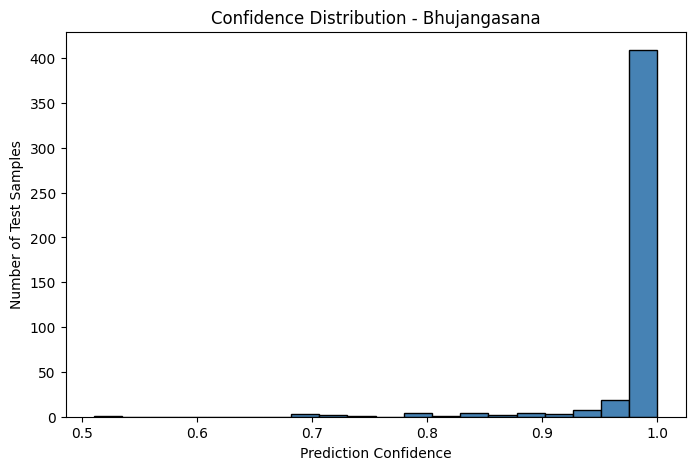

In [36]:
test_probs = rf.predict_proba(X_test)
test_confidence = test_probs.max(axis=1)  # confidence in whichever class was predicted

print(f"Average confidence : {test_confidence.mean()*100:.2f}%")
print(f"Minimum confidence : {test_confidence.min()*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(test_confidence, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Test Samples")
plt.title(f"Confidence Distribution - {POSE_NAME}")
plt.savefig(f"confidence_distribution_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Confusion Matrix

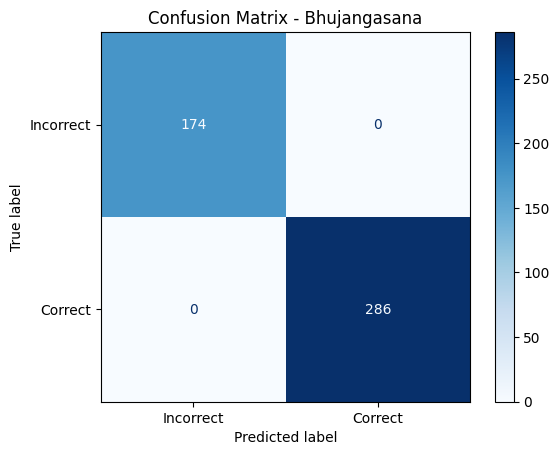

In [37]:
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {POSE_NAME}")
plt.savefig(f"confusion_matrix_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Importance

          Feature  Importance
0   left_shoulder    0.397400
1  right_shoulder    0.196057
2       left_knee    0.186758
3      right_knee    0.116906
4       right_hip    0.060821
5        left_hip    0.042059


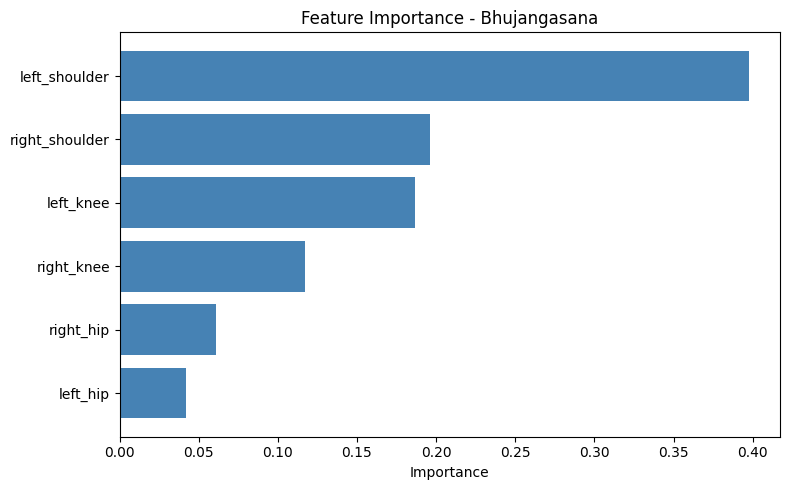

In [38]:
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.title(f"Feature Importance - {POSE_NAME}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"feature_importance_{POSE_NAME.lower().replace(' ', '_')}.png", dpi=150)
plt.show()

## Save Model and Metadata

In [39]:
joblib.dump(rf, MODEL_FILENAME)

metadata = {
    "pose_name": POSE_NAME,
    "features": FEATURES,
    "target_mapping": {"0": "Incorrect", "1": "Correct"},
    "train_accuracy": round(train_accuracy, 4),
    "val_accuracy": round(val_accuracy, 4),
    "test_accuracy": round(test_accuracy, 4),
    "test_precision": round(test_precision, 4),
    "test_recall": round(test_recall, 4),
    "test_f1_score": round(test_f1, 4),
    "n_estimators": rf.n_estimators,
    "random_state": rf.random_state
}

metadata_filename = MODEL_FILENAME.replace(".pkl", "_metadata.json")
with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Model saved as {MODEL_FILENAME}")
print(f"Metadata saved as {metadata_filename}")

Model saved as bhujangasana_rf.pkl
Metadata saved as bhujangasana_rf_metadata.json


## Test with One Sample

In [40]:
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)[0]
probabilities = rf.predict_proba(sample)[0]
confidence = probabilities[prediction]

print("Prediction :", prediction)
print(f"{'Correct' if prediction == 1 else 'Incorrect'} {POSE_NAME}")
print(f"Confidence : {confidence*100:.2f}%")
print(f"  P(Incorrect) = {probabilities[0]*100:.2f}%")
print(f"  P(Correct)   = {probabilities[1]*100:.2f}%")

Prediction : 1
Correct Bhujangasana
Confidence : 100.00%
  P(Incorrect) = 0.00%
  P(Correct)   = 100.00%
